# Trabajo Integrador: un RAG sobre seguridad en IA generativa

**Juan Cifuentes. Tecnicatura Superior en Ciencias de Datos e Inteligencia Artificial, IFTS N.º 24**
* **Materia:** Técnicas de Procesamiento de Habla (Procesamiento de Lenguaje Natural), segundo cuatrimestre de 2026

---

## Cuaderno 01: De archivos a fragmentos con procedencia

## Objetivo

Cargar los tres documentos del corpus con LangChain, revisar el texto que se extrae y cortarlos en fragmentos que guarden el archivo y la página de origen.

## Carga de los tres PDF

LangChain representa cada página de un PDF como un `Document`: `page_content` tiene el texto y `metadata` guarda la procedencia. Los tres documentos son reales y su licencia permite redistribuirlos. Una fuente real escaneada puede necesitar OCR: un cargador PDF no lo hace automáticamente.

| Archivo | Organismo | Fecha | Licencia |
|---|---|---|---|
| `owasp_top10_llm_2025.pdf` | OWASP GenAI Security Project | Versión en español, 11/03/2025 | CC BY-SA 4.0 |
| `aesia_guia11_ciberseguridad.pdf` | AESIA | Revisión del 17/07/2026 | CC BY 4.0 |
| `incibe_medidas_ia_frontera.pdf` | INCIBE | 17/06/2026 | CC BY-NC-SA 4.0 |

| Herramienta | Entrada | Salida | Qué revisar |
|---|---|---|---|
| `PyPDFLoader` | Ruta de PDF | Un `Document` por página | Texto legible, `source`, `page` (empieza en 0). |

In [ ]:
from pathlib import Path

from langchain_community.document_loaders import PyPDFLoader
from utils_visualizacion import dibujar_fragmentos

ruta_owasp = Path("datos/owasp_top10_llm_2025.pdf")
ruta_aesia = Path("datos/aesia_guia11_ciberseguridad.pdf")
ruta_incibe = Path("datos/incibe_medidas_ia_frontera.pdf")
paginas_owasp = PyPDFLoader(str(ruta_owasp)).load()
paginas_aesia = PyPDFLoader(str(ruta_aesia)).load()
paginas_incibe = PyPDFLoader(str(ruta_incibe)).load()
documentos = paginas_owasp + paginas_aesia + paginas_incibe

for documento in documentos:
    print("Fuente:", Path(documento.metadata["source"]).name)
    print("Página (si existe):", documento.metadata.get("page"))
    print("Caracteres:", len(documento.page_content))
    print("Texto de muestra:", documento.page_content[:250], "\n")

C:\Users\JUANK\AppData\Local\Temp\ipykernel_14244\389698260.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


## Lo que encontré al revisar el texto extraído

Abrí cada PDF y comparé páginas con el texto extraído. La página 8 de OWASP (la definición de inyección de prompt) sale completa y con tildes. Encontré dos problemas:

- En la guía de AESIA, las páginas 24 y 77 casi no tienen caracteres: no hay texto extraíble.
- El índice de OWASP trae líneas de puntos (`. . . .`) que pueden terminar como fragmentos sin nada útil.

## Corte en fragmentos

`RecursiveCharacterTextSplitter` intenta cortar por separaciones naturales antes de partir dentro de una palabra.

| Parámetro | Acá | Qué significa | Qué probé |
|---|---|---|---|
| `chunk_size` | 800 caracteres | Largo objetivo máximo de cada fragmento. | 250, 500, 800 y 1100 |
| `chunk_overlap` | 120 caracteres | Texto compartido entre vecinos. | 0, 80 y 120 |

Ambos son **caracteres**, no tokens; no existe un tamaño óptimo universal. El solapamiento tiene que ser menor que el tamaño.

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

divisor = RecursiveCharacterTextSplitter(chunk_size=800, chunk_overlap=120)
fragmentos = divisor.split_documents(documentos)
print("Documentos cargados:", len(documentos))
print("Fragmentos obtenidos:", len(fragmentos))

for numero in range(min(3, len(fragmentos))):
    fragmento = fragmentos[numero]
    print(f"\nFragmento {numero + 1}:", fragmento.page_content[:250])
    print("Procedencia:", fragmento.metadata)

Documentos cargados: 135
Fragmentos obtenidos: 480

Fragmento 1: OWASP PDF v4.4.1b 20250126-131847
OWASP Top 10 para
Aplicaciones de LLM
VERSIÓN 2025
Publicado el: 11 de marzo de 2025
Procedencia: {'producer': 'macOS Version 15.3.1 (Build 24D70) Quartz PDFContext, AppendMode 1.1', 'creator': 'PyPDF', 'creationdate': '', 'moddate': "D:20250312001354Z00'00'", 'source': 'datos\\owasp_top10_llm_2025.pdf', 'total_pages': 49, 'page': 0, 'page_label': '1'}

Fragmento 2: LICENSE AND USAGE
This document is licensed under Creative Commons, CC BY-SA 4.0.
You are free to:
    Share — copy and redistribute the material in any medium or format for any purpose,
        even commercially.
    Adapt — remix, transform, and bu
Procedencia: {'producer': 'macOS Version 15.3.1 (Build 24D70) Quartz PDFContext, AppendMode 1.1', 'creator': 'PyPDF', 'creationdate': '', 'moddate': "D:20250312001354Z00'00'", 'source': 'datos\\owasp_top10_llm_2025.pdf', 'total_pages': 49, 'page': 1, 'page_label': '2'}

Fragmento 

## Por qué 800 / 120

Con 250 salieron 1515 fragmentos, con 500 (el valor de la clase) 735 y con 1100, 364. Con 500 y sin solapamiento, 693. Con 800 / 120 quedaron 480, y la definición de inyección de prompt (OWASP, página 8) y el párrafo sobre el artículo 15 (AESIA, página 11) quedan enteros en un mismo fragmento. No elegí 1100 porque cada fragmento trae más texto del que pide la pregunta.

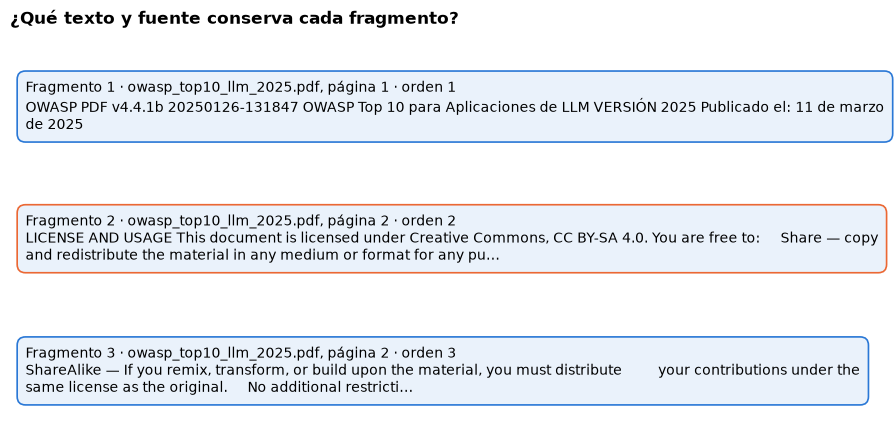

In [ ]:
fichas = []

for numero in range(min(3, len(fragmentos))):
    fragmento = fragmentos[numero]
    fuente = Path(fragmento.metadata["source"]).name
    pagina = fragmento.metadata.get("page")

    if pagina is not None:
        fuente += f", página {pagina + 1}"

    fichas.append({
        "texto": fragmento.page_content,
        "fuente": fuente,
        "inicio": numero,
    })

dibujar_fragmentos(fichas, titulo="¿Qué texto y fuente conserva cada fragmento?")

## Glosario

| Término | Qué significa acá |
|---|---|
| **Document** | Texto y metadatos reunidos en una estructura común de LangChain. |
| **Metadatos** | Información sobre la procedencia: archivo y página. |
| **Chunking** | División en fragmentos que se pueden guardar y recuperar por separado. |
| **Solapamiento** | Porción compartida entre dos fragmentos vecinos para conservar contexto. |
| **OCR** | Reconocimiento de texto en imágenes o páginas escaneadas, que `PyPDFLoader` no hace. |